# 03 · Model evaluation

Loads the metrics written by `python -m scripts.run_experiment` and puts the ML models and the baselines side by side.
No model is trained in this notebook. Every number comes from `results/metrics/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.utils import load_config
cfg = load_config(ROOT / "config.yaml")
RESULTS = ROOT / cfg["experiment"]["results_dir"]

In [2]:
import json
summary = json.loads((RESULTS / "metrics" / "run_summary.json").read_text())
print("synthetic data:", summary["synthetic_data"]); print(summary["environment"])

synthetic data: False
{'project_version': '1.0.0', 'python': '3.14.3', 'platform': 'Windows-11-10.0.26300-SP0', 'numpy': '2.4.3', 'pandas': '2.3.3', 'scikit_learn': '1.8.0', 'xgboost': '3.2.0', 'torch': '2.11.0+cpu'}


## Classification (test period)
Compare each model with the **majority-class** row: beating it is the minimum bar for useful predictions.

In [3]:
cls = pd.read_csv(RESULTS / "metrics" / "classification_metrics.csv")
cls[cls.split == "test"][["ticker", "model", "accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro", "log_loss", "brier"]].round(4)

,ticker,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,log_loss,brier
7,SPY,Majority class,0.4945,0.3333,0.1648,0.3333,0.2206,0.9428,0.5799
8,SPY,Logistic Regression,0.4965,0.3351,0.4152,0.3351,0.2255,0.9282,0.5762
9,SPY,Random Forest,0.4935,0.3327,0.1647,0.3327,0.2203,0.9305,0.5774
10,SPY,XGBoost,0.4715,0.3221,0.2751,0.3221,0.2503,0.9375,0.5831
11,SPY,LSTM,0.4925,0.3338,0.3140,0.3338,0.2378,0.9322,0.5795
12,SPY,Ensemble (soft vote),0.4925,0.3321,0.2478,0.3321,0.2214,0.9289,0.5771
13,SPY,Naive persistence,0.4196,0.3349,0.3349,0.3349,0.3347,NaN,NaN
21,AAPL,Majority class,0.4945,0.3333,0.1648,0.3333,0.2206,0.8893,0.5583
22,AAPL,Logistic Regression,0.4725,0.3241,0.2975,0.3241,0.2765,0.8888,0.5603
23,AAPL,Random Forest,0.4925,0.3349,0.3223,0.3349,0.2601,0.8886,0.5584


## Trading (test period, net of costs)

In [4]:
comp = pd.read_csv(RESULTS / "metrics" / "model_comparison_test.csv")
comp[comp.kind.isin(["baseline", "ml_confidence"])][["ticker", "strategy", "threshold", "cumulative_return", "sharpe", "sortino", "max_drawdown", "turnover_annual", "n_trades"]].round(3)

,ticker,strategy,threshold,cumulative_return,sharpe,sortino,max_drawdown,turnover_annual,n_trades
0,SPY,Buy & Hold,NaN,0.514,0.661,0.945,-0.264,0.252,1
1,SPY,MA Crossover (10/50),NaN,0.233,0.519,0.720,-0.140,6.797,27
2,SPY,Naive persistence,NaN,-0.479,-1.416,-1.792,-0.501,123.860,492
3,SPY,Logistic Regression (conf.),0.425,0.514,0.661,0.945,-0.264,0.252,1
5,SPY,Random Forest (conf.),0.300,0.514,0.661,0.945,-0.264,0.252,1
7,SPY,XGBoost (conf.),0.375,0.452,0.604,0.862,-0.265,8.811,35
9,SPY,LSTM (conf.),0.375,0.486,0.636,0.909,-0.264,0.755,3
11,SPY,Ensemble (soft vote) (conf.),0.300,0.514,0.661,0.945,-0.264,0.252,1
13,AAPL,Buy & Hold,NaN,0.524,0.506,0.732,-0.333,0.252,1
14,AAPL,MA Crossover (10/50),NaN,0.240,0.393,0.562,-0.254,7.804,31


## How the confidence threshold was chosen (validation period only)

In [5]:
t = cfg["data"]["tickers"][0]
pd.read_csv(RESULTS / "metrics" / "tuning" / f"{t}_xgboost_threshold_selection_val.csv").round(3)

,threshold,sharpe,sortino,cumulative_return,exposure,n_trades
0,0.300,1.053,1.402,0.526,1.000,1
1,0.325,1.038,1.382,0.517,0.998,3
2,0.350,1.147,1.535,0.586,0.992,7
3,0.375,1.185,1.588,0.609,0.978,19
4,0.400,1.044,1.394,0.509,0.944,41
5,0.425,0.762,1.005,0.327,0.883,75
6,0.450,0.578,0.763,0.221,0.791,117
7,0.475,0.325,0.421,0.094,0.622,147
8,0.500,0.290,0.374,0.075,0.429,165
9,0.525,0.380,0.501,0.101,0.217,104


## Hyperparameter search (purged time-series CV on the training period)

In [6]:
pd.read_csv(RESULTS / "metrics" / "tuning" / f"{t}_xgboost_search.csv").head(10).round(4)

,max_depth,learning_rate,n_estimators,class_weight,cv_log_loss_mean,cv_log_loss_std,cv_macro_f1_mean,fit_seconds
0,2,0.03,100,NaN,0.9979,0.0580,0.2795,1.0235
1,3,0.03,100,NaN,1.0043,0.0627,0.2888,1.2820
2,5,0.03,100,NaN,1.0179,0.0653,0.2938,2.0834
3,2,0.03,300,NaN,1.0206,0.0690,0.3021,2.6974
4,2,0.10,100,NaN,1.0271,0.0716,0.3033,1.2752
5,3,0.03,300,NaN,1.0416,0.0770,0.3074,4.2932
6,5,0.03,100,balanced,1.0497,0.0379,0.3640,2.0869
7,3,0.10,100,NaN,1.0548,0.0862,0.3065,1.7549
8,3,0.03,300,balanced,1.0618,0.0516,0.3676,4.7073
9,2,0.03,300,balanced,1.0644,0.0419,0.3666,3.9475


## Statistical uncertainty: block-bootstrap 95% intervals

In [7]:
pd.read_csv(RESULTS / "metrics" / "bootstrap_confidence_intervals.csv").round(3)

,ticker,strategy,statistic,estimate,low,high,share_positive
0,SPY,Buy & Hold,sharpe,0.661,-0.213,1.582,0.936
1,SPY,MA Crossover (10/50),sharpe,0.519,-0.412,1.555,0.856
2,SPY,MA Crossover (10/50),sharpe_minus_buy_and_hold,-0.143,-0.877,0.567,0.334
3,SPY,Naive persistence,sharpe,-1.416,-2.470,-0.390,0.004
4,SPY,Naive persistence,sharpe_minus_buy_and_hold,-2.077,-2.867,-1.302,0.000
5,SPY,Logistic Regression (conf.),sharpe,0.661,-0.198,1.540,0.932
6,SPY,Logistic Regression (conf.),sharpe_minus_buy_and_hold,0.000,0.000,0.000,0.000
7,SPY,Random Forest (conf.),sharpe,0.661,-0.143,1.581,0.937
8,SPY,Random Forest (conf.),sharpe_minus_buy_and_hold,0.000,0.000,0.000,0.000
9,SPY,XGBoost (conf.),sharpe,0.604,-0.218,1.561,0.927


## Walk-forward (annual retraining)

In [8]:
wf_path = RESULTS / "metrics" / "walk_forward_trading.csv"
if wf_path.exists():
    display(pd.read_csv(wf_path)[["ticker", "strategy", "start", "end", "cumulative_return", "sharpe", "max_drawdown"]].round(3))
    display(pd.read_csv(RESULTS / "metrics" / "walk_forward_classification.csv").round(4))

,ticker,strategy,start,end,cumulative_return,sharpe,max_drawdown
0,SPY,Buy & Hold,2016-01-04,2025-12-29,3.020,0.896,-0.320
1,SPY,MA Crossover (10/50),2016-01-04,2025-12-29,1.183,0.744,-0.155
2,SPY,Logistic Regression (conf.),2016-01-04,2025-12-29,0.503,0.339,-0.417
3,SPY,Random Forest (conf.),2016-01-04,2025-12-29,1.835,0.702,-0.362
4,SPY,XGBoost (conf.),2016-01-04,2025-12-29,0.700,0.409,-0.405
5,SPY,LSTM (conf.),2016-01-04,2025-12-29,0.975,0.509,-0.330
6,SPY,Ensemble (soft vote) (conf.),2016-01-04,2025-12-29,0.841,0.464,-0.393
7,AAPL,Buy & Hold,2016-01-04,2025-12-29,10.435,0.981,-0.374
8,AAPL,MA Crossover (10/50),2016-01-04,2025-12-29,4.003,0.875,-0.290
9,AAPL,Logistic Regression (conf.),2016-01-04,2025-12-29,1.495,0.495,-0.459


,ticker,model_key,model,period,n,accuracy,balanced_accuracy,f1_macro,log_loss,brier
0,SPY,logistic_regression,Logistic Regression,2016-2025,2512,0.4936,0.3325,0.2559,0.9624,0.5928
1,SPY,random_forest,Random Forest,2016-2025,2512,0.4968,0.3312,0.2380,0.9618,0.5909
2,SPY,xgboost,XGBoost,2016-2025,2512,0.4642,0.3253,0.2894,0.9808,0.6065
3,SPY,lstm,LSTM,2016-2025,2512,0.4932,0.3340,0.2648,0.9648,0.5930
4,SPY,ensemble,Ensemble (soft vote),2016-2025,2512,0.4896,0.3296,0.2535,0.9616,0.5916
5,SPY,majority_class,Majority class,2016-2025,2512,0.5036,0.3333,0.2233,0.9713,0.5917
6,AAPL,logistic_regression,Logistic Regression,2016-2025,2512,0.4885,0.3363,0.3212,0.8938,0.5639
7,AAPL,random_forest,Random Forest,2016-2025,2512,0.5052,0.3338,0.2866,0.8843,0.5545
8,AAPL,xgboost,XGBoost,2016-2025,2512,0.4845,0.3357,0.3225,0.9013,0.5671
9,AAPL,lstm,LSTM,2016-2025,2512,0.4976,0.3366,0.3126,0.8946,0.5601


## Key figures

**classification_comparison.png**

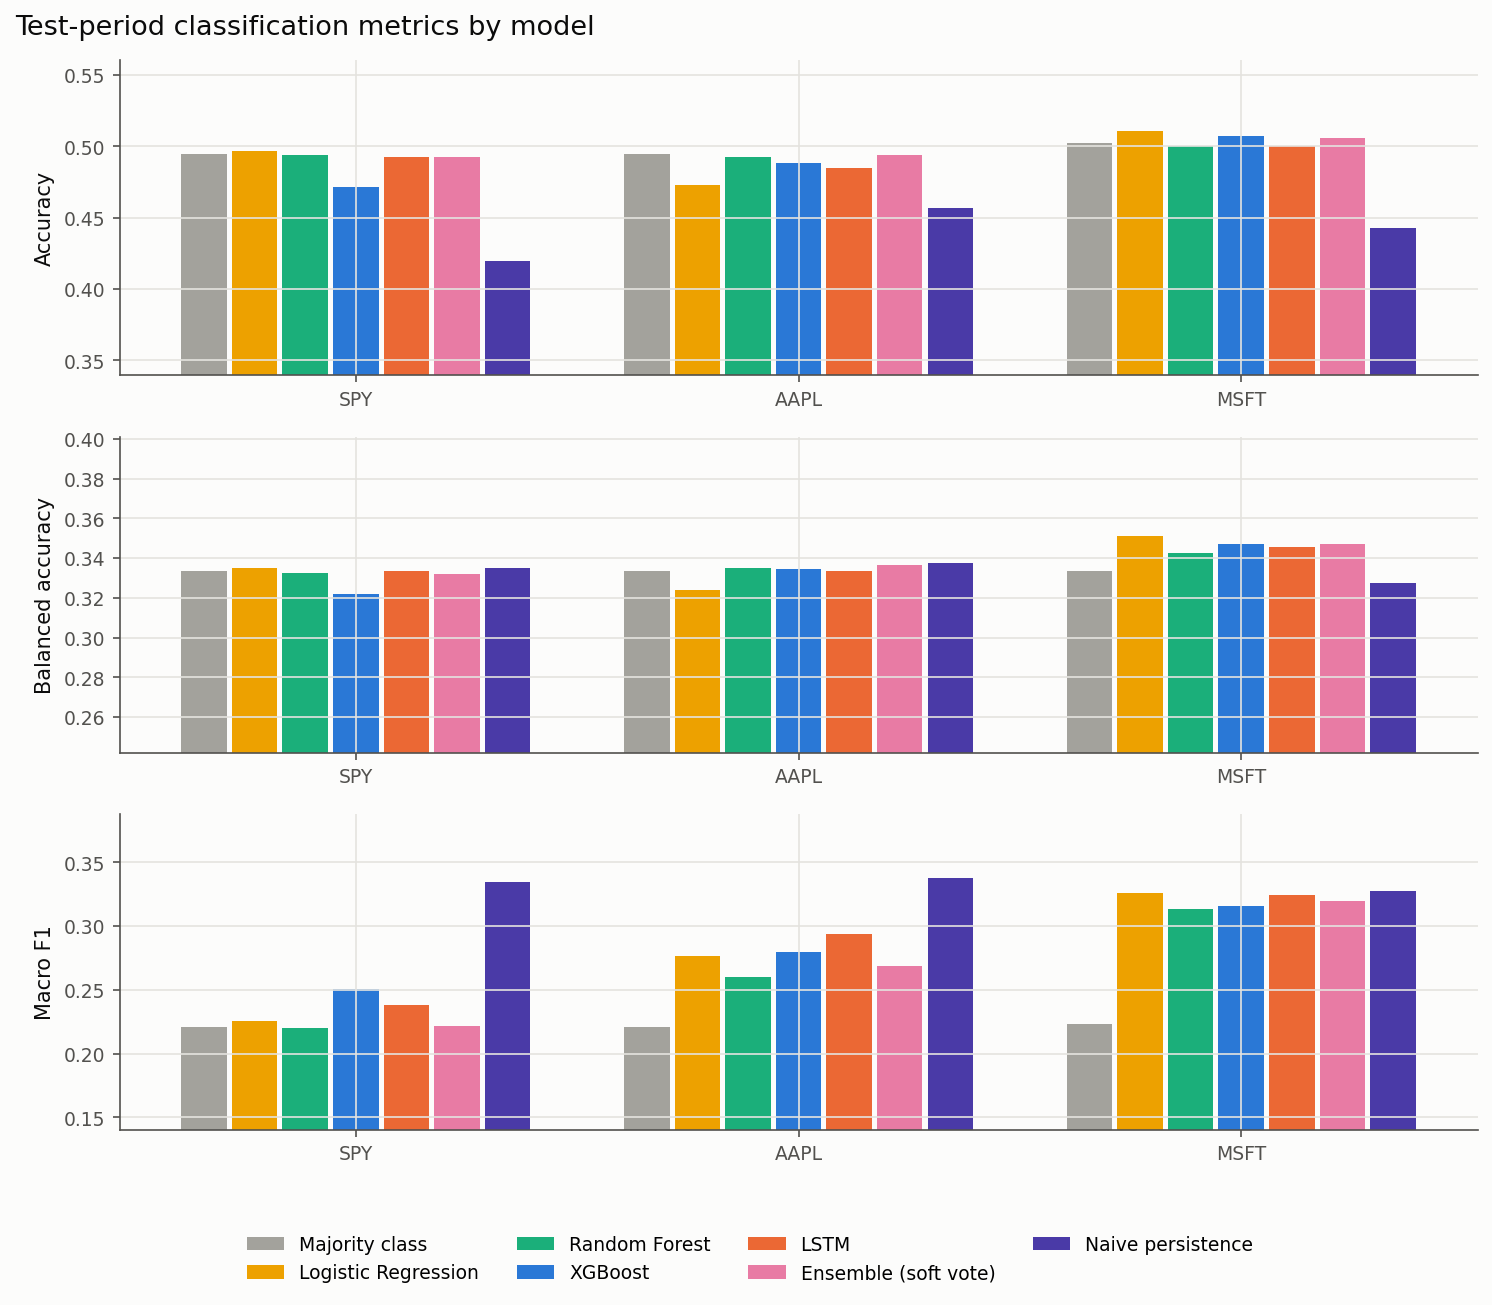

**sharpe_comparison.png**

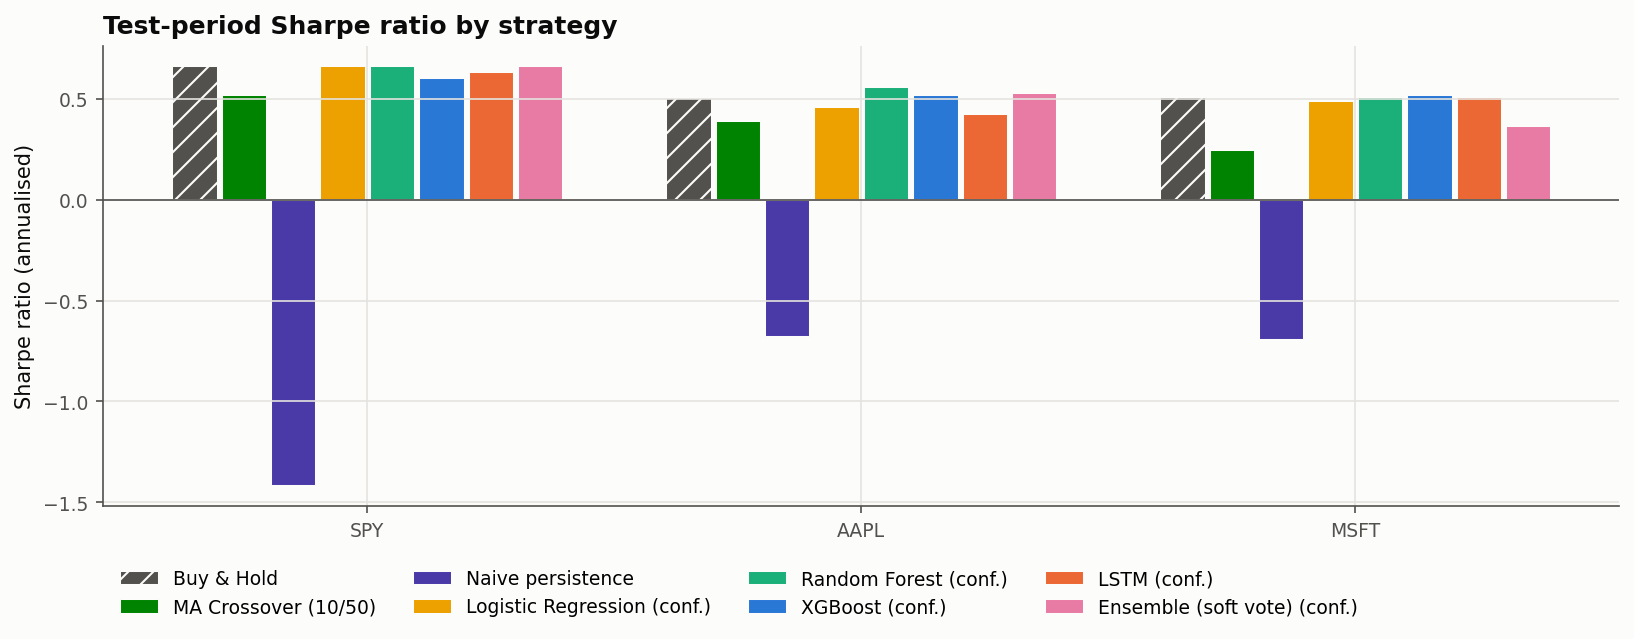

**SPY_equity_curves.png**

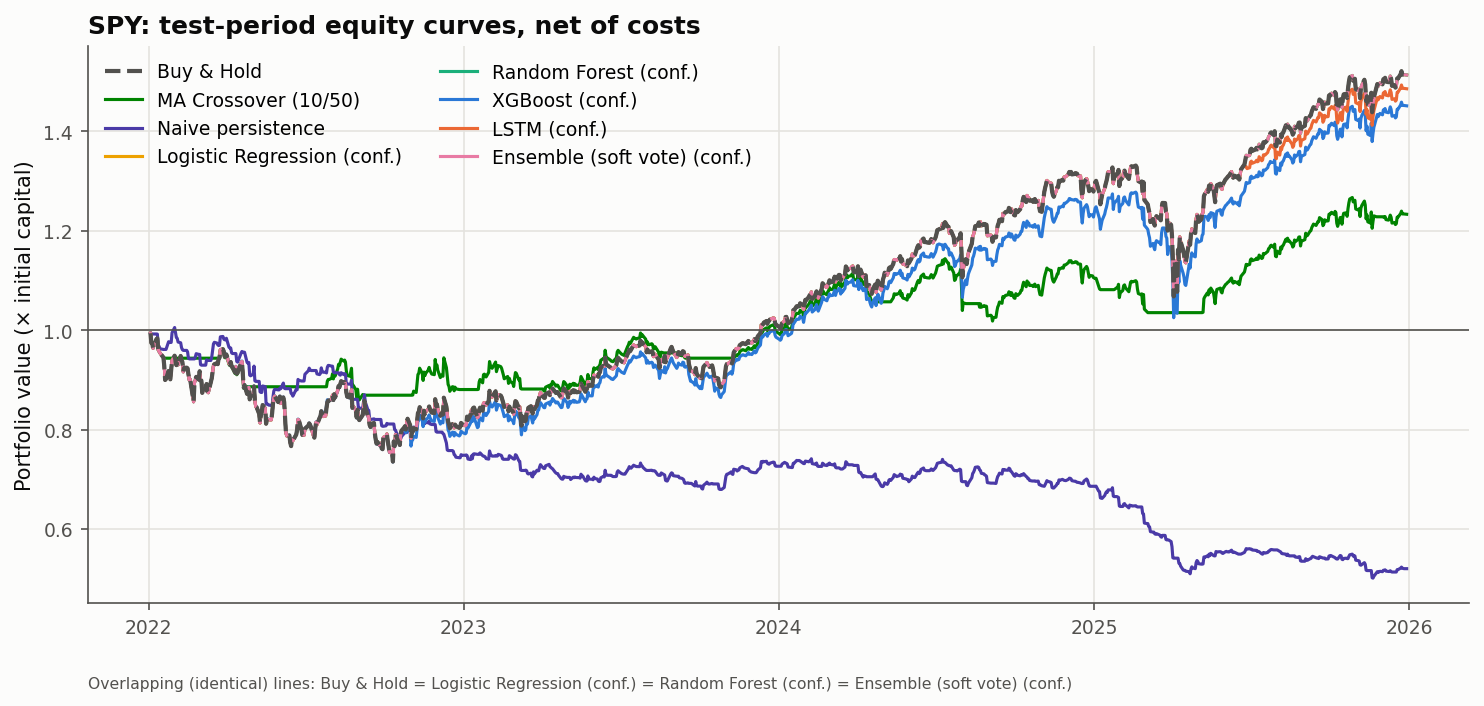

**SPY_confusion_matrices.png**

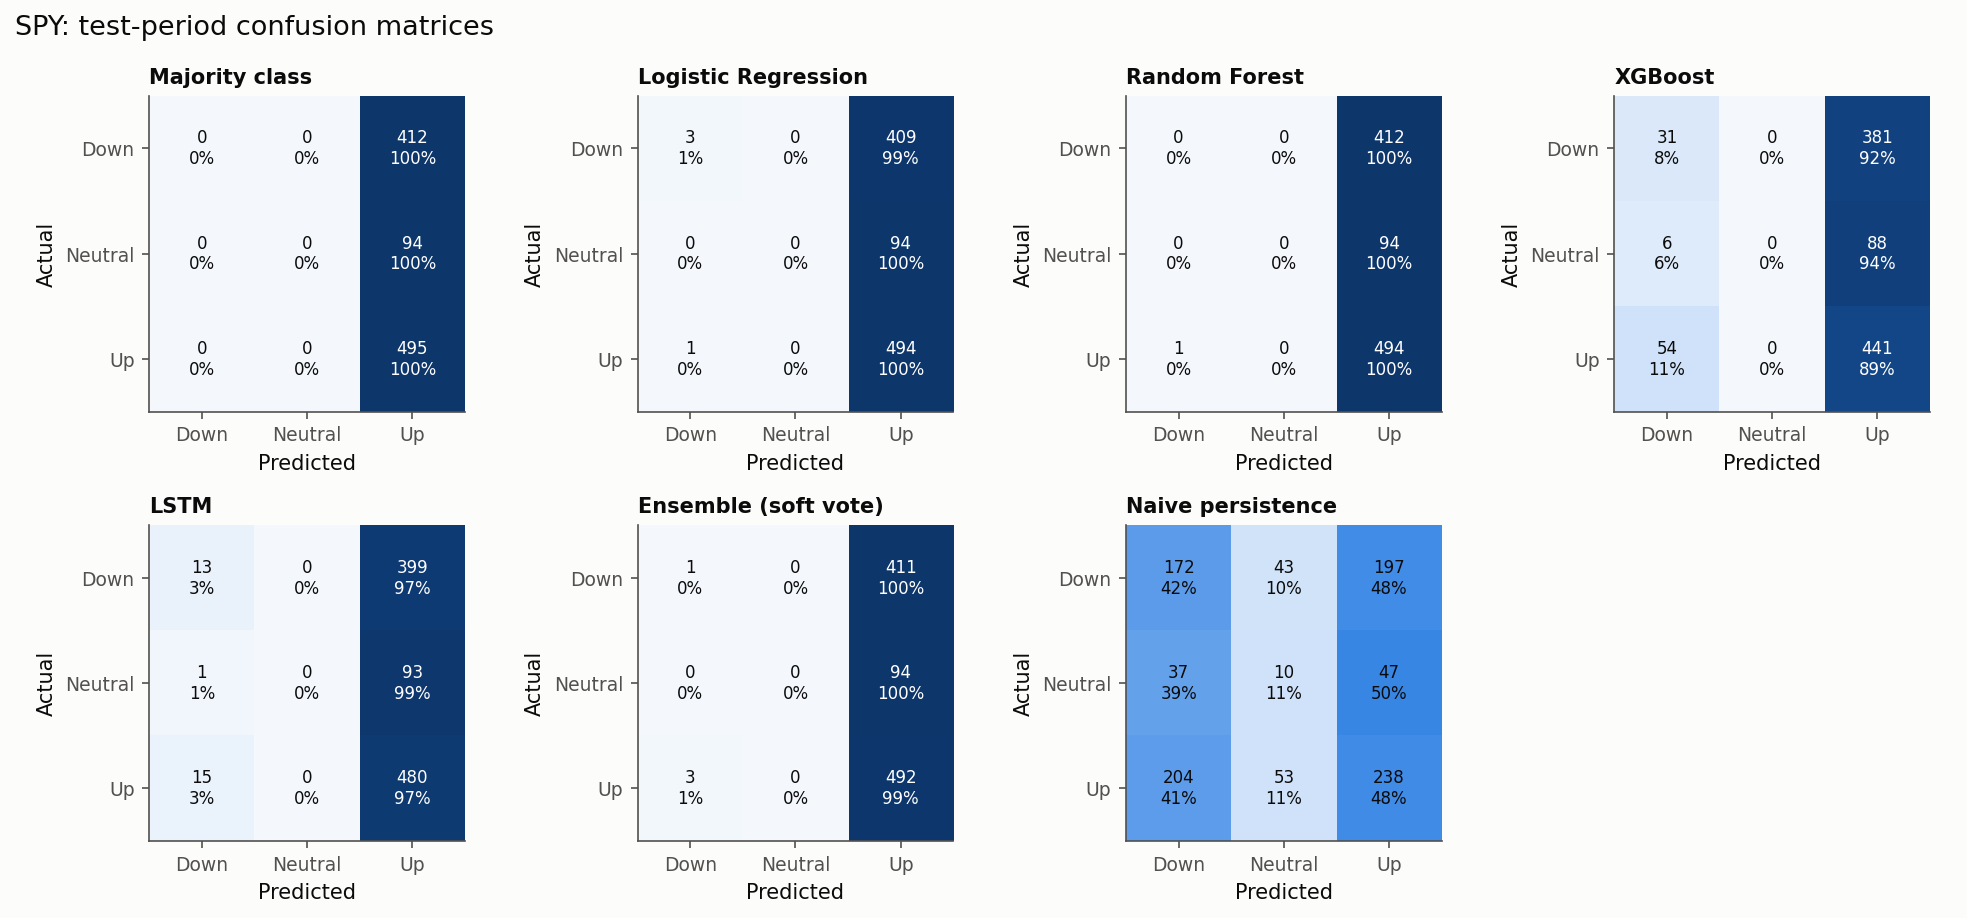

**SPY_reliability.png**

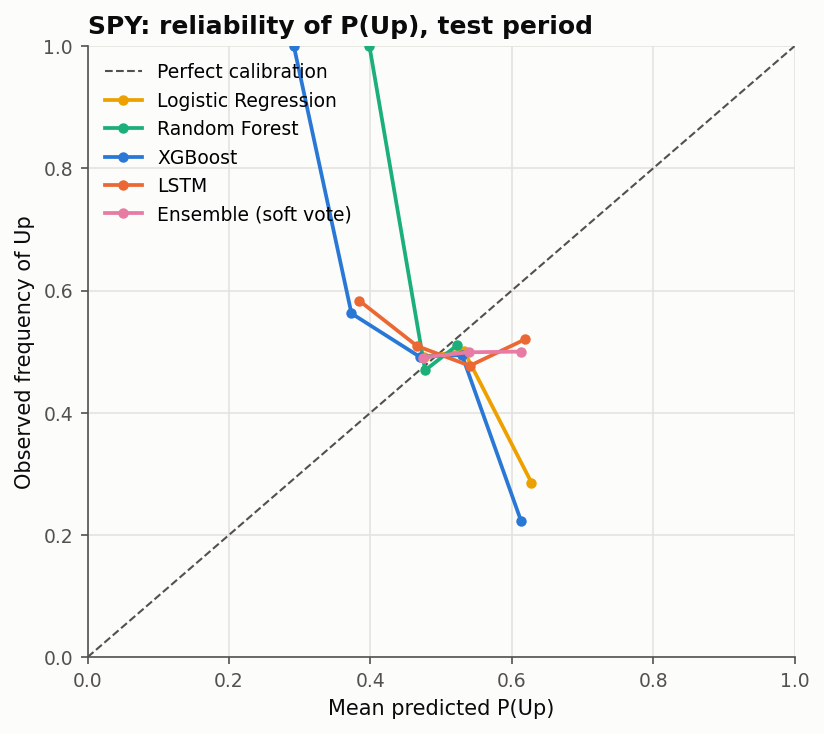

**cost_sensitivity.png**

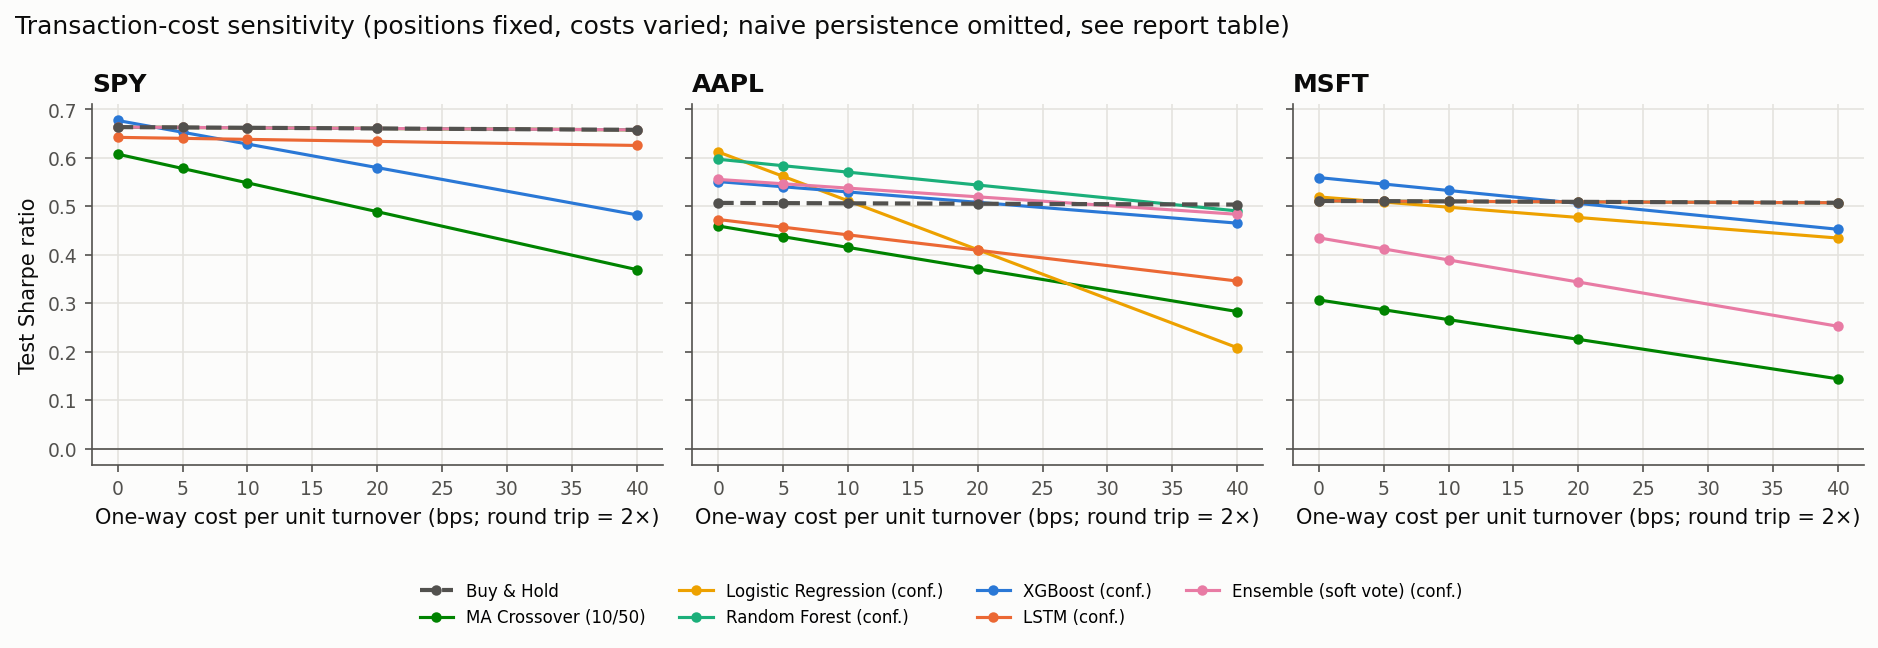

**walk_forward_sharpe.png**

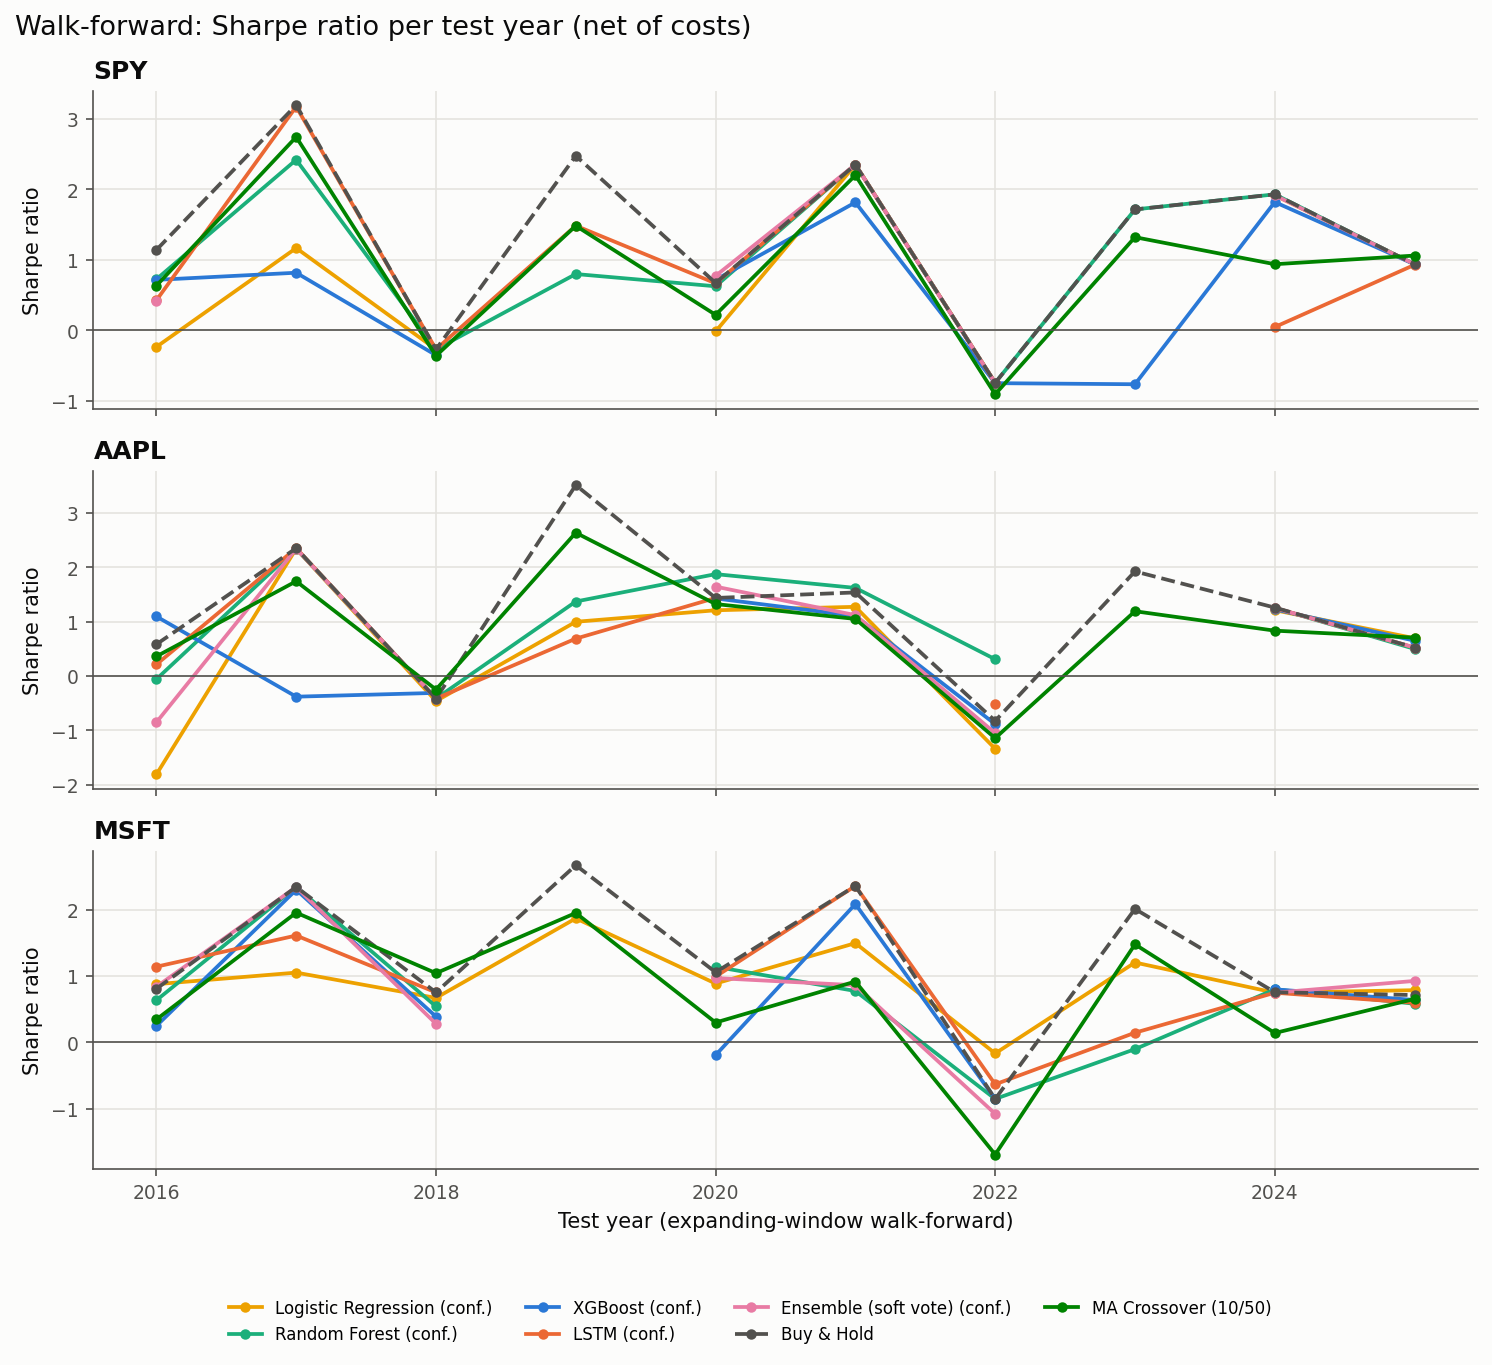

In [9]:
for name in ["classification_comparison.png", "sharpe_comparison.png", f"{t}_equity_curves.png", f"{t}_confusion_matrices.png",
             f"{t}_reliability.png", "cost_sensitivity.png", "walk_forward_sharpe.png"]:
    p = RESULTS / "figures" / name
    if p.exists():
        display(Markdown(f"**{name}**")); display(Image(filename=str(p)))